# Pair 3: Virtual hotel tours from phone video

**Name: Arnob Deb, Student ID: 60841338.**

A travel platform wants hotels to offer virtual tours made from ordinary phone video. This notebook compares
two ways of building a 3D scene from the same frames.

Model Used: 

Platform A: Nerfacto. Platform B: Splatfacto
Baseline: Nearest frame shows the closest training frame with no 3D model

How to use it: Run every cell from top to bottom. If results holds all 12 results then notebook
shows them and skips training. So it needs no Docker or GPU. To repeat the experiment, rename results
and processed and you need to keep the phone videos in videos and run again. That needs an NVIDIA GPU with 8 GB,
Docker Desktop with GPU access and about 3 hours on an RTX 4060 Ti.
Finished models are skipped if a run stops. QUICK = True runs a short setup check into results_quick.

In [ ]:
import csv, random, shutil, subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, Video, display
from PIL import Image, ImageDraw

QUICK = False  # True: train one scene for 300 steps, saved to results_quick. Don't report those numbers.
IMAGE = "ghcr.io/nerfstudio-project/nerfstudio:latest"  # Official image with Nerfstudio, COLMAP, ffmpeg and CUDA.

try:
    HERE = Path(__vsc_ipynb_file__).parent
except NameError:
    HERE = Path.cwd()
VIDEOS, RESULTS = HERE / "videos", HERE / ("results_quick" if QUICK else "results")
print(f"Using the files in {HERE}")

Using the files in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair3_virtual_tours


## 1. Code that runs inside the container

Nerfstudio is hard to install on Windows so I ran in its official Docker image. The four cells
below write the scripts the container runs into this folder, so this notebook is their only source.

Preparing the scenes: Each video is cut to 150 evenly spaced frames and COLMAP works out where the
camera was for each one. Two problems found during this evaluation are handled: COLMAP ran out of memory
on 4K vide. So videos are first shrunk to 1920 pixels on the long side and COLMAP split the video into
pieces. Nerfstudio reads the first and the largest piece is used. Every 8th frame is held out for testing.
full.json trains on all the other frames and reduced.json on half of them with the same test views.

In [ ]:
%%writefile prepare_scenes.py

import json, shutil, struct, subprocess
from pathlib import Path

HERE = Path(__file__).resolve().parent
VIDEOS, PROCESSED = HERE / "videos", HERE / "processed"
FRAMES, TEST_EVERY, LONG_SIDE, MIN_SHARE = 150, 8, 1920, 0.8
FIRST, RETRY, RECORD = "sequential", "exhaustive", "matching_used.txt"  


def resize(video):
    out = PROCESSED / "_resized" / f"{video.stem}.mp4"
    if not out.exists():
        out.parent.mkdir(parents=True, exist_ok=True)
        size = f"scale='if(gt(iw,ih),{LONG_SIDE},-2)':'if(gt(iw,ih),-2,{LONG_SIDE})'"  
        partial = out.with_suffix(".partial.mp4")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(video), "-vf", size, "-crf", "18", "-preset", "veryfast", "-an", str(partial)], check=True)
        partial.rename(out)  
    return out


def colmap(video, output, method):
    subprocess.run(["ns-process-data", "video", "--data", str(resize(video)), "--output-dir", str(output),
                    "--num-frames-target", str(FRAMES), "--matching-method", method, "--no-gpu"], check=True)


def placed(model):
    return struct.unpack("<Q", (model / "images.bin").read_bytes()[:8])[0]  


def frames_in(output):
    file = output / "transforms.json"
    return len(json.loads(file.read_text())["frames"]) if file.exists() else 0


def share(output):
    return frames_in(output) / len(list((output / "images").glob("*")))  


def use_largest_model(output):
    sparse = output / "colmap" / "sparse"
    models = sorted(f for f in sparse.iterdir() if (f / "images.bin").exists()) if sparse.exists() else []
    model = max(models, key=placed, default=None)
    if model is None or placed(model) == frames_in(output):
        return
    print(f"{output.name}: using {model.name}, which placed {placed(model)} frames")
    refine = subprocess.run(["colmap", "bundle_adjuster", "--input_path", str(model), "--output_path", str(model),
                             "--BundleAdjustment.refine_principal_point", "1"], capture_output=True, text=True)
    if refine.returncode != 0:
        raise SystemExit(refine.stderr[-2000:])
    subprocess.run(["ns-process-data", "images", "--data", str(output / "images"), "--output-dir", str(output), "--skip-colmap",
                    "--skip-image-processing", "--colmap-model-path", str(model.relative_to(output))], check=True)


def prepare(video, output):
    if (output / "transforms.json").exists():
        print(f"{video.stem}: COLMAP has already run")
    else:
        if output.exists():
            shutil.rmtree(output) 
        colmap(video, output, FIRST)
    use_largest_model(output)
    if share(output) < MIN_SHARE and not (output / RECORD).exists():
        print(f"{video.stem}: {share(output):.0%} of frames placed, so trying {RETRY} matching")
        retry = output.with_name(f"{output.name}_retry")
        if retry.exists():
            shutil.rmtree(retry)
        colmap(video, retry, RETRY)
        use_largest_model(retry)
        better = share(retry) > share(output)  
        shutil.rmtree(output if better else retry)
        if better:
            retry.rename(output)
        (output / RECORD).write_text(RETRY if better else FIRST)
    if frames_in(output) == 0:
        raise SystemExit(f"COLMAP couldn't place any frames in {video.stem}. Film it again more slowly.")


videos = sorted(p for p in VIDEOS.iterdir() if p.suffix.lower() in {".mp4", ".mov"})
if not videos:
    raise SystemExit(f"No videos found. Put your .mp4 or .mov files in {VIDEOS}")
summary = []
for video in videos:
    output = PROCESSED / video.stem
    prepare(video, output)
    meta = json.loads((output / "transforms.json").read_text())
    names = sorted(f["file_path"] for f in meta["frames"])
    test = names[::TEST_EVERY]
    train = [n for n in names if n not in test]
    for name, frames in [("full", train), ("reduced", train[::2])]: 
        (output / f"{name}.json").write_text(json.dumps({**meta, "train_filenames": frames, "val_filenames": test, "test_filenames": test}, indent=2))
    record = output / RECORD
    row = {"scene": video.stem, "frames_extracted": len(list((output / "images").glob("*"))), "frames_matched": len(names),
           "matched_share": round(share(output), 3), "matching": record.read_text() if record.exists() else FIRST,
           "train_frames_full": len(train), "train_frames_reduced": len(train[::2]), "test_frames": len(test)}
    summary.append(row)
    print(row)
    if share(output) < MIN_SHARE:
        print(f"WARNING: only {share(output):.0%} of frames matched in {video.stem}. Film it again more slowly.")
(PROCESSED / "scene_summary.json").write_text(json.dumps(summary, indent=2))

Overwriting prepare_scenes.py


Training and testing

I have used Nerfstudio's default 30,000 training steps for each model with half-resolution images and seed 42 to keep the experiments consistent. I have disabled camera optimisation for Nerfacto because it only adjusts training cameras not test cameras which could affect the evaluation results. Splatfacto already has this setting disabled by default.

After training, I have used ns-eval to evaluate the models on held-out views and save the results. I have also used measure_speed.py to measure rendering speed and ns-render to generate walkthrough videos. Then saved the results after each model and skipped completed models to avoid repeating the training.

In [ ]:
%%writefile run_evaluation.py
# Trains and tests each model on each scene. Runs inside the container. --quick is a short check, not for reporting.
import argparse, csv, json, subprocess, threading, time
from importlib import metadata
from pathlib import Path

HERE = Path(__file__).resolve().parent
PROCESSED = HERE / "processed"
DOWNSCALE, SEED = 2, 42  
MODEL_OPTIONS = {"nerfacto": ["--pipeline.model.camera-optimizer.mode", "off"],
                 "splatfacto": ["--pipeline.datamanager.cache-images", "cpu"]}  
DATA_OPTIONS = {"nerfacto": [], "splatfacto": ["--load-3D-points", "True"]}  
COLUMNS = ["scene", "model", "frames", "status", "train_frames", "test_frames", "iterations", "psnr", "ssim", "lpips",
           "render_fps", "train_minutes", "peak_gpu_gb", "storage_mb"]


def watch_gpu(peak, stop):
    while not stop.wait(2):
        out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
        try:
            peak[0] = max(peak[0] or 0, float(out.strip().splitlines()[0]))
        except (ValueError, IndexError):
            pass 


def run_logged(command, log_path):

    with log_path.open("a", encoding="utf-8") as log:
        log.write("\n$ " + " ".join(command) + "\n")
        log.flush()
        return subprocess.run(command, stdout=log, stderr=subprocess.STDOUT).returncode == 0


def run_model(scene, model, frames, iterations, outputs, results):
 
    experiment, name = f"{scene.name}_{frames}", f"{scene.name}__{model}__{frames}"
    (results / "logs").mkdir(exist_ok=True)
    log = results / "logs" / f"{name}.log"
    data_file = scene / f"{frames}.json"
    meta = json.loads(data_file.read_text())
    row = {"scene": scene.name, "model": model, "frames": frames, "status": "failed", "train_frames": len(meta["train_filenames"]),
           "test_frames": len(meta["test_filenames"]), "iterations": iterations}

    print(f"Training {name}. Follow progress in {log}")
    peak, stop = [None], threading.Event()
    watcher = threading.Thread(target=watch_gpu, args=(peak, stop), daemon=True)
    watcher.start()
    started = time.perf_counter()
    trained = run_logged(["ns-train", model, "--data", str(data_file), "--output-dir", str(outputs), "--experiment-name", experiment,
                          "--timestamp", "run", "--max-num-iterations", str(iterations), "--machine.seed", str(SEED),
                          "--vis", "tensorboard",  
                          "--steps-per-eval-all-images", "1000000",  
                          *MODEL_OPTIONS[model], "nerfstudio-data", "--downscale-factor", str(DOWNSCALE), *DATA_OPTIONS[model]], log)
    row["train_minutes"] = round((time.perf_counter() - started) / 60, 2)
    stop.set()
    watcher.join()
    row["peak_gpu_gb"] = round(peak[0] / 1024, 2) if peak[0] else None
    if not trained:
        print(f"FAILED: {name}. See the end of {log}")
        return row

    run_dir = outputs / experiment / model / "run"
    config = run_dir / "config.yml"
    row["storage_mb"] = round(sum(p.stat().st_size for p in (run_dir / "nerfstudio_models").rglob("*") if p.is_file()) / 1024**2, 1)
    eval_file = results / "evals" / f"{name}.json"
    eval_file.parent.mkdir(exist_ok=True)
    if not run_logged(["ns-eval", "--load-config", str(config), "--output-path", str(eval_file), "--render-output-path", str(results / "renders" / name)], log):
        print(f"FAILED during testing: {name}. See the end of {log}")
        return row
    scores = json.loads(eval_file.read_text())["results"]
    row.update(psnr=scores["psnr"], ssim=scores["ssim"], lpips=scores["lpips"], status="done")

    speed = subprocess.run(["python", str(HERE / "measure_speed.py"), str(config)], capture_output=True, text=True)
    try:
        row["render_fps"] = json.loads(speed.stdout.strip().splitlines()[-1])["render_fps"]
    except (ValueError, IndexError, KeyError):  
        print(f"Couldn't measure drawing speed for {name}")
        with log.open("a", encoding="utf-8") as file:
            file.write(speed.stdout + speed.stderr)
    if frames == "full": 
        video = results / "videos" / f"{name}.mp4"
        video.parent.mkdir(exist_ok=True)
        run_logged(["ns-render", "interpolate", "--load-config", str(config), "--output-path", str(video), "--pose-source", "eval",
                    "--interpolation-steps", "6", "--frame-rate", "24"], log)
    return row


def run_baseline(scene, frames, results):

    output = results / "evals" / f"{scene.name}__nearest-frame__{frames}.json"
    finished = subprocess.run(["python", str(HERE / "baseline_nearest_frame.py"), str(scene), frames, "--output", str(output)])
    meta = json.loads((scene / f"{frames}.json").read_text())
    row = {"scene": scene.name, "model": "nearest-frame", "frames": frames, "status": "failed",
           "train_frames": len(meta["train_filenames"]), "test_frames": len(meta["test_filenames"])}
    if finished.returncode == 0:
        row.update(json.loads(output.read_text()), status="done")
    return row


def save_table(rows, path):
    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=COLUMNS, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


parser = argparse.ArgumentParser()
parser.add_argument("--iterations", type=int, default=30000) 
parser.add_argument("--quick", action="store_true")
args = parser.parse_args()
scenes = sorted(p for p in PROCESSED.iterdir() if (p / "full.json").exists())
if not scenes:
    raise SystemExit("No prepared scenes found. Run prepare_scenes.py first.")
levels, iterations = ["full", "reduced"], args.iterations
if args.quick:
    scenes, levels, iterations = scenes[:1], ["full"], 300
results, outputs = HERE / ("results_quick" if args.quick else "results"), HERE / ("outputs_quick" if args.quick else "outputs")
results.mkdir(exist_ok=True)
table = results / "metrics.csv"
rows = [r for r in csv.DictReader(table.open(encoding="utf-8")) if r["status"] == "done"] if table.exists() else []
finished = {(r["scene"], r["model"], r["frames"]) for r in rows}  
for scene in scenes:
    for frames in levels:
        if (scene.name, "nearest-frame", frames) not in finished:
            (results / "evals").mkdir(exist_ok=True)
            rows.append(run_baseline(scene, frames, results))
            save_table(rows, table)
        for model in MODEL_OPTIONS:
            if (scene.name, model, frames) in finished:
                print(f"Already finished: {scene.name} {model} {frames}")
                continue
            rows.append(run_model(scene, model, frames, iterations, outputs, results))
            save_table(rows, table)

try:
    version = metadata.version("nerfstudio")  
except metadata.PackageNotFoundError:
    version = None
environment = {"nerfstudio": version, "colmap": subprocess.run(["colmap", "-h"], capture_output=True, text=True).stdout.splitlines()[:2],
               "gpu": subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip(),
               "settings": {"iterations": iterations, "downscale": DOWNSCALE, "seed": SEED, "model_options": MODEL_OPTIONS, "data_options": DATA_OPTIONS}}
(results / "environment.json").write_text(json.dumps(environment, indent=2))
print(f"\nFinished. Results are in {table}. Failed runs: {sum(r['status'] != 'done' for r in rows)}")

Overwriting run_evaluation.py


The nearest-frame baseline: A hotel could skip 3D and show its closest existing photo. For each test
view, this picks the training frame with the closest camera position and direction and scores it with the same metrics Nerfstudio uses.
If a 3D model can't beat this its extra cost isn't justified.

In [4]:
%%writefile baseline_nearest_frame.py
# Scores the nearest training frame against each test view. Runs inside the container.
import argparse, json
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torchmetrics.functional import structural_similarity_index_measure
from torchmetrics.image import PeakSignalNoiseRatio
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity

parser = argparse.ArgumentParser()
parser.add_argument("scene", type=Path)
parser.add_argument("frames", choices=["full", "reduced"])
parser.add_argument("--output", type=Path, required=True)
args = parser.parse_args()
meta = json.loads((args.scene / f"{args.frames}.json").read_text())
by_name = {f["file_path"]: f for f in meta["frames"]}
train, test = [by_name[n] for n in meta["train_filenames"]], [by_name[n] for n in meta["test_filenames"]]


def pose(frame):
    m = np.array(frame["transform_matrix"])
    return m[:3, 3], -m[:3, 2]  # Camera position, and viewing direction (it looks along the negative third column).


def image(frame):
    path = args.scene / "images_2" / Path(frame["file_path"]).name  # Half size, like the models.
    return torch.from_numpy(np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0).permute(2, 0, 1)[None].to(device)


positions = np.array([pose(f)[0] for f in train])
scale = float(np.median(np.linalg.norm(np.diff(positions, axis=0), axis=1))) or 1.0  # Typical step between neighbouring frames.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)  # The same metric settings as Nerfstudio.
lpips = LearnedPerceptualImagePatchSimilarity(normalize=True).to(device)
scores = {"psnr": [], "ssim": [], "lpips": []}
with torch.no_grad():
    for frame in test:
        position, direction = pose(frame)
        best, best_score = None, float("inf")
        for other in train:  # Closest position plus angle, with one typical step equal to 10 degrees.
            p, d = pose(other)
            score = np.linalg.norm(position - p) / scale + np.degrees(np.arccos(np.clip(direction @ d, -1.0, 1.0))) / 10.0
            if score < best_score:
                best, best_score = other, score
        truth, shown = image(frame), image(best)
        scores["psnr"].append(float(psnr(truth, shown)))
        scores["ssim"].append(float(structural_similarity_index_measure(truth, shown)))
        scores["lpips"].append(float(lpips(truth, shown)))
result = {key: float(np.mean(values)) for key, values in scores.items()}
args.output.parent.mkdir(parents=True, exist_ok=True)
args.output.write_text(json.dumps(result, indent=2))
print(result)

Overwriting baseline_nearest_frame.py


### Drawing speed

This times the drawing step alone, because a virtual tour must respond smoothly.

In [5]:
%%writefile measure_speed.py
# Times the drawing step alone, because ns-eval's timer also counts scoring and saving. Runs inside the container.
import json, sys, time
from pathlib import Path

import torch
from nerfstudio.utils.eval_utils import eval_setup

_, pipeline, _, _ = eval_setup(Path(sys.argv[1]), test_mode="test")
timings = []
with torch.no_grad():
    for index, (camera, _) in enumerate(pipeline.datamanager.fixed_indices_eval_dataloader):
        torch.cuda.synchronize()  # Wait for earlier GPU work, so the timer is exact.
        started = time.perf_counter()
        pipeline.model.get_outputs_for_camera(camera=camera)
        torch.cuda.synchronize()
        if index > 0:  # The first view includes one-off setup work.
            timings.append(time.perf_counter() - started)
print(json.dumps({"render_fps": len(timings) / sum(timings)}))  # run_evaluation.py reads this line.

Overwriting measure_speed.py


## 2. Run the experiment

If all results are already saved, this skips Docker. Otherwise it runs the two steps in the container,
showing their output as it arrives.

In [6]:
def in_container(*command):
    """Run one command in the Nerfstudio container, with this folder as /workspace."""
    docker = ["docker", "run", "--gpus", "all", "--rm", "--shm-size=12gb",  # Docker's default shared memory is too small.
              "-v", f"{HERE}:/workspace", "-v", "nerfstudio-cache:/root/.cache", "-w", "/workspace", IMAGE, *command]
    process = subprocess.Popen(docker, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    for line in process.stdout:
        print(line, end="")
    if process.wait() != 0:
        raise SystemExit(f"This step failed in the container: {' '.join(command)}")


videos = sorted(p for p in VIDEOS.iterdir() if p.suffix.lower() in {".mp4", ".mov"}) if VIDEOS.exists() else []
table = RESULTS / "metrics.csv"
done = (pd.read_csv(table)["status"] == "done").sum() if table.exists() else 0
if done >= (3 if QUICK else 6 * max(len(videos), 2)):  # 3 methods x 2 frame levels per scene.
    print(f"All results are already saved in {RESULTS}, so the experiment is skipped.")
elif not videos:
    raise SystemExit(f"No videos found. Put your .mp4 or .mov files in {VIDEOS}")
elif shutil.which("docker") is None or subprocess.run(["docker", "info"], capture_output=True).returncode != 0:
    raise SystemExit("Docker isn't running. Install Docker Desktop, open it, then run this cell again.")
else:
    in_container("python", "prepare_scenes.py")
    in_container("python", "run_evaluation.py", *(["--quick"] if QUICK else []))

All results are already saved in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair3_virtual_tours\results, so the experiment is skipped.


## 3. Results

PSNR, SSIM and LPIPS compare each drawn view with the real held-out frame, which Week 8 calls a
verifiable task. Peak GPU memory covers the whole card.

In [7]:
summary_file = HERE / "processed" / "scene_summary.json"
display(pd.read_json(summary_file) if summary_file.exists() else "The processed folder isn't here, so the scene table can't be shown.")
metrics = pd.read_csv(RESULTS / "metrics.csv")
display(metrics[metrics["status"] != "done"])  # Any failed runs.
display(metrics[["scene", "frames", "model", "train_frames", "test_frames", "psnr", "ssim", "lpips"]].round(3))
display(metrics.loc[metrics["model"] != "nearest-frame", ["scene", "frames", "model", "render_fps", "train_minutes", "peak_gpu_gb", "storage_mb"]].round(2))
print((RESULTS / "environment.json").read_text())

,scene,frames_extracted,frames_matched,matched_share,matching,train_frames_full,train_frames_reduced,test_frames
0,place1,158,158,1,sequential,138,69,20
1,place2,162,162,1,sequential,141,71,21


,scene,model,frames,status,train_frames,test_frames,iterations,psnr,ssim,lpips,render_fps,train_minutes,peak_gpu_gb,storage_mb


,scene,frames,model,train_frames,test_frames,psnr,ssim,lpips
0,place1,full,nearest-frame,138,20,17.980,0.627,0.269
1,place1,full,nerfacto,138,20,27.474,0.953,0.061
2,place1,full,splatfacto,138,20,35.058,0.967,0.049
3,place1,reduced,nearest-frame,69,20,17.941,0.628,0.276
4,place1,reduced,nerfacto,69,20,26.893,0.951,0.062
5,place1,reduced,splatfacto,69,20,34.923,0.965,0.049
6,place2,full,nearest-frame,141,21,17.452,0.630,0.310
7,place2,full,nerfacto,141,21,26.283,0.954,0.064
8,place2,full,splatfacto,141,21,35.773,0.973,0.046
9,place2,reduced,nearest-frame,71,21,17.601,0.636,0.293


,scene,frames,model,render_fps,train_minutes,peak_gpu_gb,storage_mb
1,place1,full,nerfacto,0.79,17.51,4.56,167.8
2,place1,full,splatfacto,198.75,11.01,1.46,145.9
4,place1,reduced,nerfacto,0.79,17.34,4.55,167.8
5,place1,reduced,splatfacto,224.34,10.91,1.33,142.0
7,place2,full,nerfacto,0.79,17.71,4.56,167.8
8,place2,full,splatfacto,217.72,11.46,2.18,161.0
10,place2,reduced,nerfacto,0.79,17.67,4.56,167.8
11,place2,reduced,splatfacto,207.44,11.25,1.39,157.2


{
  "nerfstudio": "1.1.5",
  "colmap": [
    "COLMAP 3.9.1 -- Structure-from-Motion and Multi-View Stereo",
    "(Commit e9903641 on 2024-01-08 with CUDA)"
  ],
  "gpu": "NVIDIA GeForce RTX 4060 Ti, 610.88",
  "settings": {
    "iterations": 30000,
    "downscale": 2,
    "seed": 42,
    "model_options": {
      "nerfacto": [
        "--pipeline.model.camera-optimizer.mode",
        "off"
      ],
      "splatfacto": [
        "--pipeline.datamanager.cache-images",
        "cpu"
      ]
    },
    "data_options": {
      "nerfacto": [],
      "splatfacto": [
        "--load-3D-points",
        "True"
      ]
    }
  }
}


## 4. Colour check

Phone cameras change brightness and colour as they move. Nerfacto learns a colour setting per training
frame and averages them for a test view; Splatfacto has none. Right shapes with slightly wrong brightness
lose a lot of PSNR. Each image `ns-eval` saved holds the real view on the left and the model's on the
right. This scores each view raw, and again after fitting a brightness and contrast change per colour
channel. The fit looks at the real view, which a real tour couldn't, so the matched score is only a
diagnosis and raw PSNR stays the headline result.

In [8]:
def view_psnr(real, drawn):
    return float(-10 * np.log10(np.mean((real - drawn) ** 2)))


def scores_for(folder):
    """Raw and colour-matched PSNR for each saved test view of one trained model."""
    raw, matched = [], []
    for path in sorted(folder.glob("eval_img_*.png")):
        pixels = np.asarray(Image.open(path).convert("RGB"), dtype=np.float64) / 255
        real, drawn = pixels[:, : pixels.shape[1] // 2], pixels[:, pixels.shape[1] // 2 :]
        fitted = np.empty_like(drawn)
        for c in range(3):  # Fit gain * drawn + offset to the real view, per colour channel.
            gain, offset = np.polyfit(drawn[..., c].ravel(), real[..., c].ravel(), 1)
            fitted[..., c] = gain * drawn[..., c] + offset
        raw.append(view_psnr(real, drawn))
        matched.append(view_psnr(real, np.clip(fitted, 0, 1)))
    return np.array(raw), np.array(matched)


RENDERS, rows = RESULTS / "renders", []
for scene in sorted({p.name.split("__")[0] for p in RENDERS.glob("*__nerfacto__*")}):
    for frames in ["full", "reduced"]:
        folders = {m: RENDERS / f"{scene}__{m}__{frames}" for m in ["nerfacto", "splatfacto"]}
        if not all(f.exists() for f in folders.values()):
            continue
        (n_raw, n_match), (s_raw, s_match) = scores_for(folders["nerfacto"]), scores_for(folders["splatfacto"])
        rows.append({"scene": scene, "frames": frames, "test_views": len(n_raw),
                     "nerfacto_raw": round(float(n_raw.mean()), 2), "splatfacto_raw": round(float(s_raw.mean()), 2),
                     "nerfacto_matched": round(float(n_match.mean()), 2), "splatfacto_matched": round(float(s_match.mean()), 2),
                     "raw_gap": round(float((s_raw - n_raw).mean()), 2), "matched_gap": round(float((s_match - n_match).mean()), 2),
                     "splatfacto_wins_raw": int(np.sum(s_raw - n_raw > 0)), "splatfacto_wins_matched": int(np.sum(s_match - n_match > 0))})
pd.DataFrame(rows).to_csv(RESULTS / "colour_check.csv", index=False)
display(pd.DataFrame(rows))

,scene,frames,test_views,nerfacto_raw,splatfacto_raw,nerfacto_matched,splatfacto_matched,raw_gap,matched_gap,splatfacto_wins_raw,splatfacto_wins_matched
0,place1,full,20,27.47,35.03,33.40,35.65,7.56,2.25,20,17
1,place1,reduced,20,26.89,34.90,32.64,35.34,8.01,2.70,20,18
2,place2,full,21,26.28,35.75,33.80,36.22,9.47,2.43,21,17
3,place2,reduced,21,25.74,35.22,33.17,35.77,9.48,2.59,21,18


## 5. Charts

Saved in `results/figures`.

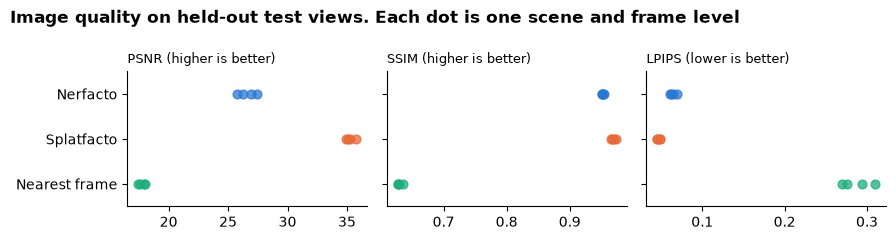

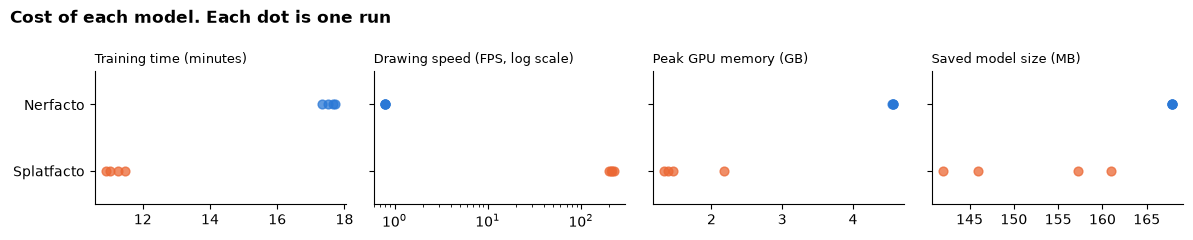

In [9]:
COLOURS = {"nerfacto": "#2a78d6", "splatfacto": "#eb6834", "nearest-frame": "#1baf7a"}
LABELS = {"nerfacto": "Nerfacto", "splatfacto": "Splatfacto", "nearest-frame": "Nearest frame"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
(RESULTS / "figures").mkdir(exist_ok=True)
done = metrics[metrics["status"] == "done"]
charts = [("fig1_quality.png", "Image quality on held-out test views. Each dot is one scene and frame level", list(COLOURS),
           [("psnr", "PSNR (higher is better)"), ("ssim", "SSIM (higher is better)"), ("lpips", "LPIPS (lower is better)")]),
          ("fig2_costs.png", "Cost of each model. Each dot is one run", ["nerfacto", "splatfacto"],
           [("train_minutes", "Training time (minutes)"), ("render_fps", "Drawing speed (FPS, log scale)"), ("peak_gpu_gb", "Peak GPU memory (GB)"), ("storage_mb", "Saved model size (MB)")])]
for file, title, models, panels in charts:
    fig, axes = plt.subplots(1, len(panels), figsize=(3 * len(panels), 2.4), sharey=True)
    for axis, (column, heading) in zip(axes, panels):
        for row, model in enumerate(models):
            values = done.loc[done["model"] == model, column].dropna()
            axis.scatter(values, [row] * len(values), color=COLOURS[model], s=40, alpha=0.75, zorder=3)
        axis.set_xscale("log" if column == "render_fps" else "linear")
        axis.set_title(heading, loc="left", fontsize=9)
    axes[0].set_yticks(range(len(models)), [LABELS[m] for m in models])
    axes[0].set_ylim(len(models) - 0.5, -0.5)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(RESULTS / "figures" / file)
    plt.show()

## 6. Blind rating

Whether a view looks real is a non-verifiable question in Week 8's terms. For 5 test views per scene,
this builds an image of the real photo beside the two models' views in random order, as View X and View Y,
so the rater can't tell which model made which. Rate each from 1 to 5 in `results/rating/rating_sheet.csv`,
then again at least 24 hours later without looking at round 1. Open `rating_key.csv` only after both
rounds. An existing sheet is never replaced, because it holds the ratings. The seed was changed from 8410
before the final rating, because the first key had been opened.

In [10]:
RATING = RESULTS / "rating"
if not (RATING / "rating_sheet.csv").exists():
    RATING.mkdir(parents=True, exist_ok=True)
    rng, sheet, key = random.Random(20261106), [], []
    for scene in sorted({p.name.split("__")[0] for p in RENDERS.glob("*__nerfacto__full")}):
        files = {m: sorted((RENDERS / f"{scene}__{m}__full").glob("eval_img_*.png")) for m in ["nerfacto", "splatfacto"]}
        step = max(len(files["nerfacto"]) // 5, 1)  # 5 views spread evenly across the test frames.
        for number, (n_file, s_file) in enumerate(list(zip(files["nerfacto"][::step], files["splatfacto"][::step]))[:5]):
            halves = []
            for path in (n_file, s_file):  # Each saved image is the real view, then the model's view.
                image = Image.open(path).convert("RGB")
                w, h = image.size
                halves.append((image.crop((0, 0, w // 2, h)), image.crop((w // 2, 0, w, h))))
            order = [("nerfacto", halves[0][1]), ("splatfacto", halves[1][1])]
            rng.shuffle(order)
            truth, (w, h) = halves[0][0], halves[0][0].size
            panel = Image.new("RGB", (w * 3, h + 24), "white")
            for i, (picture, label) in enumerate([(truth, "Real photo"), (order[0][1], "View X"), (order[1][1], "View Y")]):
                panel.paste(picture, (i * w, 24))
                ImageDraw.Draw(panel).text((i * w + 6, 6), label, fill="black")
            name = f"{scene}_view{number + 1}.png"
            panel.save(RATING / name)
            sheet.append({"image": name, "round1_view_x": "", "round1_view_y": "", "round2_view_x": "", "round2_view_y": ""})
            key.append({"image": name, "view_x": order[0][0], "view_y": order[1][0]})
    pd.DataFrame(sheet).to_csv(RATING / "rating_sheet.csv", index=False)
    pd.DataFrame(key).to_csv(RATING / "rating_key.csv", index=False)
    print(f"Made {len(sheet)} comparison images in {RATING}")

sheet = pd.read_csv(RATING / "rating_sheet.csv").merge(pd.read_csv(RATING / "rating_key.csv"), on="image")
if sheet[["round2_view_x", "round2_view_y"]].notna().all().all():  # Both rounds finished.
    ratings = pd.DataFrame([{"image": r.image, "model": getattr(r, f"view_{v}"), "round1": getattr(r, f"round1_view_{v}"),
                             "round2": getattr(r, f"round2_view_{v}")} for v in ["x", "y"] for r in sheet.itertuples()])
    ratings["mean_rating"] = (ratings["round1"] + ratings["round2"]) / 2
    ratings.to_csv(RESULTS / "ratings_by_model.csv", index=False)
    print(f"Rounds matched exactly on {(ratings['round1'] == ratings['round2']).mean():.0%} of ratings.")  # Is one rater's judgement stable?
    print(f"Correlation between the two rounds: {ratings['round1'].corr(ratings['round2']):.2f}")
    display(ratings.groupby("model")[["round1", "round2", "mean_rating"]].mean().round(2))
else:
    print("Round 2 isn't finished, so the ratings aren't summarised yet.")

Rounds matched exactly on 70% of ratings.
Correlation between the two rounds: 0.30


,round1,round2,mean_rating
model,,,
nerfacto,4.8,4.8,4.8
splatfacto,4.5,4.7,4.6


## 7. Input-to-output demo

The input is a phone video; the output is a 3D model that draws views the camera never kept. Each panel
shows a real held-out view beside both models' views, in blind order. The videos are walkthroughs drawn
by each model from the full data.

place1_view1.png


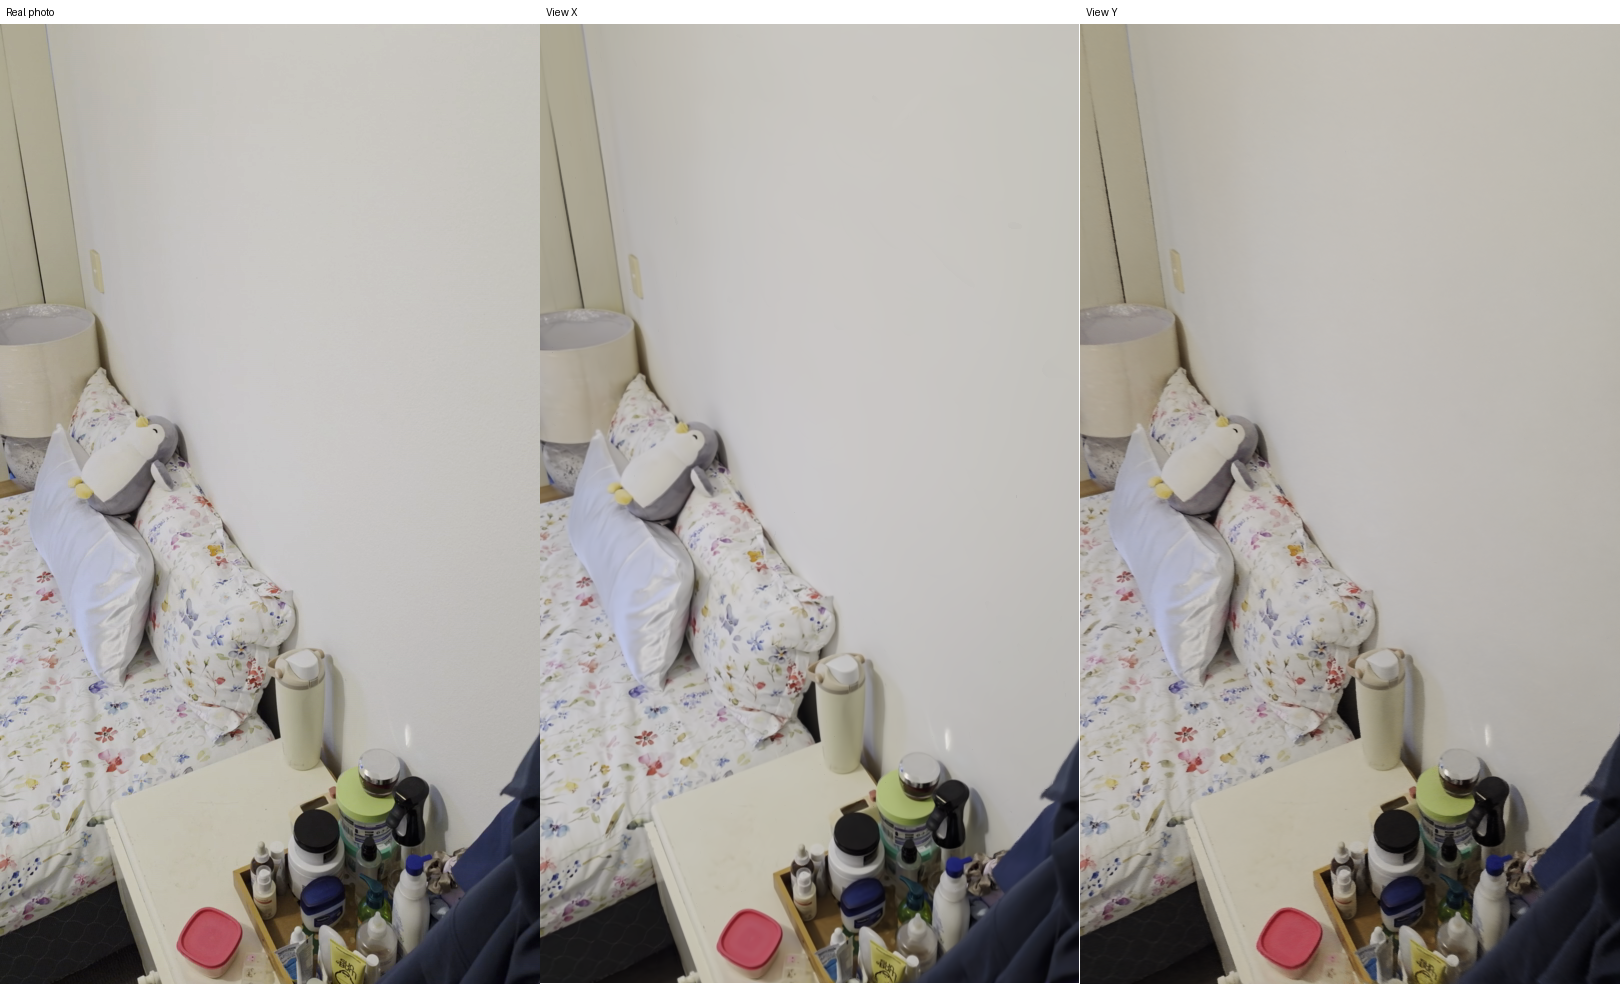

place2_view1.png


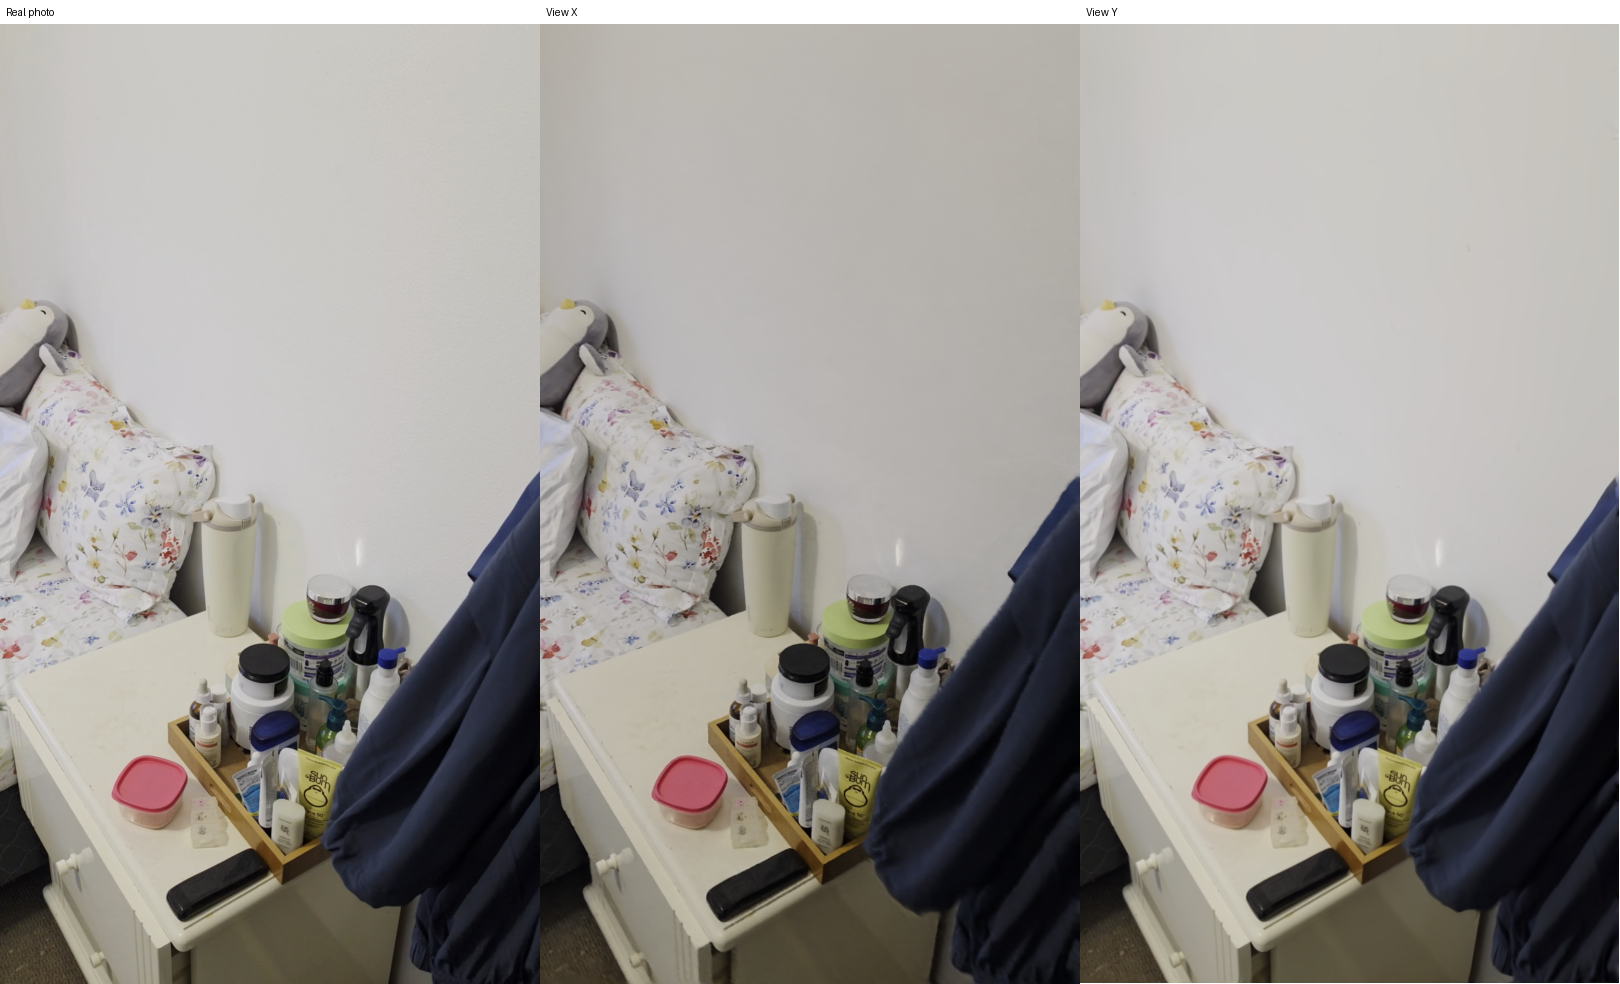

place1__nerfacto__full.mp4


place1__splatfacto__full.mp4


place2__nerfacto__full.mp4


place2__splatfacto__full.mp4


In [11]:
for panel in sorted(RATING.glob("*_view1.png")):
    print(panel.name)
    display(ShowImage(filename=str(panel), width=800))
for video in sorted((RESULTS / "videos").glob("*.mp4")):  # Kept as separate files, so the notebook stays small.
    print(video.name)
    display(Video(str(video.relative_to(HERE)), embed=False, width=320))